# <span style="color:#154360;">Método de Interpolación Iterada de Neville</span>
### **Métodos Numéricos I**

Joselin Guadalupe López Martínez


## <span style="color:#1F618D;">1. Formulación del Problema y Fundamento del Método</span>

Dados $n + 1$ puntos distintos $(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)$ donde $y_i = f(x_i)$, el método de **Neville** permite calcular el valor del polinomio interpolante $P(x)$ de grado a lo sumo $n$ en un punto específico $x$, evaluando de manera recursiva polinomios de grado creciente sin construir su forma algebraica explícita.

### Recurrencia del Algoritmo 3.1
Definimos $Q_{i,j}$ como el polinomio de Lagrange de grado $j$ que interpola los nodos $x_{i-j}, x_{i-j+1}, \dots, x_i$. La tabla triangular inferior se construye mediante:

$$Q_{i,0} = f(x_i), \quad \text{para } i = 0, 1, \dots, n$$

$$Q_{i,j} = \frac{(x - x_{i-j}) Q_{i,j-1} - (x - x_i) Q_{i-1,j-1}}{x_i - x_{i-j}}, \quad \text{para } 1 \le j \le i \le n$$

La mejor aproximación obtenida con todos los nodos corresponde al elemento final $Q_{n,n}$.

## <span style="color:#1F618D;">2. Prueba del Algoritmo: Ejemplo 2 (Burden, pág. 89)</span>

Se requiere aproximar $f(1.5)$ a partir de los siguientes 5 nodos tabulados:

| $i$ | $x_i$ | $f(x_i)$ |
| :---: | :---: | :---: |
| 0 | $1.0$ | $0.7651977$ |
| 1 | $1.3$ | $0.6200860$ |
| 2 | $1.6$ | $0.4554022$ |
| 3 | $1.9$ | $0.2818186$ |
| 4 | $2.2$ | $0.1103623$ |

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def neville(x_eval, x_nodos, y_nodos):
    x = np.asarray(x_nodos, dtype=float)
    y = np.asarray(y_nodos, dtype=float)

    n = len(x) - 1
    Q = np.zeros((n + 1, n + 1), dtype=float)

    # Columna inicial Q_{i,0} = f(x_i)
    Q[:, 0] = y

    # Construcción iterativa de la tabla de Neville (Algoritmo 3.1)
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            numerador = (x_eval - x[i - j]) * Q[i, j - 1] - (x_eval - x[i]) * Q[i - 1, j - 1]
            denominador = x[i] - x[i - j]
            Q[i, j] = numerador / denominador

    return Q

**3.- EJECUCION DE LA TABLA Y GRAFICA**

,x_i,"Q_i,0","Q_i,1","Q_i,2","Q_i,3","Q_i,4"
0,1.0,0.765198,,,,
1,1.3,0.620086,0.523345,,,
2,1.6,0.455402,0.510297,0.512471,,
3,1.9,0.281819,0.513263,0.511286,0.511813,
4,2.2,0.110362,0.510427,0.513736,0.51183,0.51182



Aproximación final P(1.5) = 0.5118200


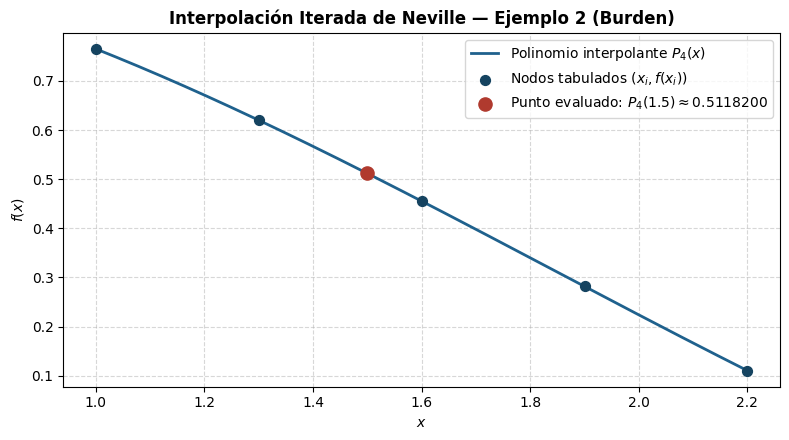

In [6]:
# Datos del Ejemplo
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x_objetivo = 1.5

# Cálculo de la tabla Q
Q_matriz = neville(x_objetivo, x_datos, y_datos)
resultado_final = Q_matriz[-1, -1]

# Presentación tabular limpia con pandas
nombres_col = [f"Q_i,{j}" for j in range(len(x_datos))]
df = pd.DataFrame(Q_matriz, columns=nombres_col)
df.insert(0, "x_i", x_datos)

# Ocultamos los ceros de la parte triangular superior para mejor lectura
df_limpio = df.astype(object)
for i in range(len(x_datos)):
    for j in range(i + 1, len(x_datos)):
        df_limpio.iloc[i, j + 1] = ""

display(df_limpio)
print(f"\nAproximación final P({x_objetivo}) = {resultado_final:.7f}")

# Gráfica del polinomio interpolante y el punto evaluado
x_curva = np.linspace(min(x_datos), max(x_datos), 200)
y_curva = [neville(val, x_datos, y_datos)[-1, -1] for val in x_curva]

plt.figure(figsize=(8, 4.5))
plt.plot(x_curva, y_curva, color="#1F618D", linewidth=2, label="Polinomio interpolante $P_4(x)$")
plt.scatter(x_datos, y_datos, color="#154360", s=50, zorder=5, label="Nodos tabulados $(x_i, f(x_i))$")
plt.scatter([x_objetivo], [resultado_final], color="#B03A2E", s=90, zorder=6,
            label=f"Punto evaluado: $P_4({x_objetivo}) \\approx {resultado_final:.7f}$")

plt.title("Interpolación Iterada de Neville — Ejemplo 2 (Burden)", fontsize=12, fontweight="bold")
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## <span style="color:#1F618D;">4. Solución Final</span>

> **Resultado obtenido:** Al evaluar el polinomio interpolante de grado 4 mediante el método de Neville en $x = 1.5$, se obtiene:
> $$Q_{4,4} = P(1.5) \approx \mathbf{0.5118200}$$
